# Real-Time Face Detection Benchmark

Comparing **YuNet** (OpenCV's current deep-learning face detector, ONNX) at three internal
input resolutions — quantifying the classic engineering trade-off: **speed vs sensitivity**.

Test video: 732 frames of people walking (Intel sample video, 1920×1080).
All measurements on this machine; FPS is decode + inference + post-processing.

In [1]:
import sys, json
sys.path.insert(0, "..")

import cv2
import numpy as np

from src.detectors import YuNetDetector, draw_faces
from src.benchmark import benchmark_video

## 1. Benchmark each configuration

In [2]:
results = {}
for size in [(160, 160), (320, 320), (640, 640)]:
    det = YuNetDetector(input_size=size)
    results[det.name] = benchmark_video(det, "assets/face-walking.mp4")
    print(det.name, "->", results[det.name])

[ WARN:0@0.011] global net_impl_backend.cpp:345 setPreferableTarget Targets are not supported by the new graph engine for now


YuNet 160x160 -> {'detector': 'YuNet 160x160', 'frames_processed': 732, 'fps': 336.6, 'mean_faces_per_frame': 0.127, 'frames_with_detection': '75/732', 'mean_confidence': 0.757}


[ WARN:0@2.193] global net_impl_backend.cpp:345 setPreferableTarget Targets are not supported by the new graph engine for now


YuNet 320x320 -> {'detector': 'YuNet 320x320', 'frames_processed': 732, 'fps': 257.59, 'mean_faces_per_frame': 0.504, 'frames_with_detection': '221/732', 'mean_confidence': 0.797}


[ WARN:0@5.041] global net_impl_backend.cpp:345 setPreferableTarget Targets are not supported by the new graph engine for now


YuNet 640x640 -> {'detector': 'YuNet 640x640', 'frames_processed': 732, 'fps': 162.47, 'mean_faces_per_frame': 0.594, 'frames_with_detection': '273/732', 'mean_confidence': 0.829}


## 2. Speed vs sensitivity table

In [3]:
import pandas as pd
tbl = pd.DataFrame([
    {
        "detector": det,
        "fps": r["fps"],
        "mean_faces_per_frame": r["mean_faces_per_frame"],
        "mean_confidence": r["mean_confidence"],
    }
    for det, r in results.items()
]).round(3)
tbl

,detector,fps,mean_faces_per_frame,mean_confidence
0,YuNet 160x160,336.60,0.127,0.757
1,YuNet 320x320,257.59,0.504,0.797
2,YuNet 640x640,162.47,0.594,0.829


## 3. Visualize the trade-off

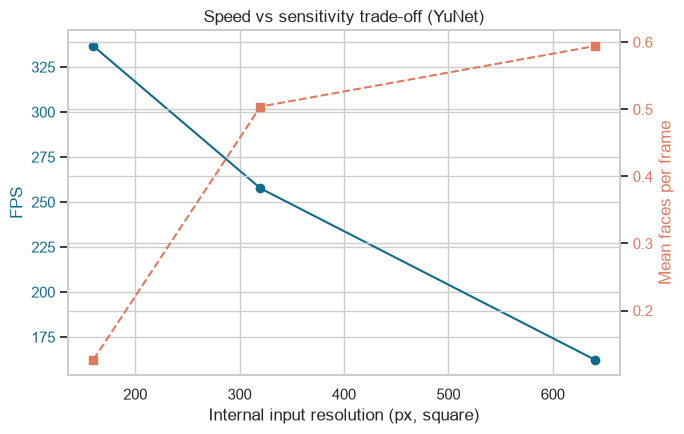

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

fig, ax1 = plt.subplots(figsize=(7, 4.5))
x = [int(d.split()[1].split("x")[0]) for d in tbl["detector"]]
ax1.plot(x, tbl["fps"], "o-", color="#0f6b8c", label="FPS (speed)")
ax1.set_xlabel("Internal input resolution (px, square)")
ax1.set_ylabel("FPS", color="#0f6b8c")
ax1.tick_params(axis="y", labelcolor="#0f6b8c")

ax2 = ax1.twinx()
ax2.plot(x, tbl["mean_faces_per_frame"], "s--", color="#e07a5f", label="faces / frame (sensitivity)")
ax2.set_ylabel("Mean faces per frame", color="#e07a5f")
ax2.tick_params(axis="y", labelcolor="#e07a5f")

ax1.set_title("Speed vs sensitivity trade-off (YuNet)")
fig.tight_layout()
fig.savefig("images/tradeoff.png", dpi=150)
plt.show()

## 4. Live demo — detect on a frame

In [5]:
# load a frame that contains faces
cap = cv2.VideoCapture("assets/face-walking.mp4")
best_frame, best_faces = None, []
det = YuNetDetector(input_size=(320, 320))
for _ in range(300):
    ok, frame = cap.read()
    if not ok:
        break
    faces = det.detect(frame)
    if len(faces) > len(best_faces):
        best_frame, best_faces = frame, faces
cap.release()

annotated = draw_faces(best_frame, best_faces, show_confidence=True)
cv2.imwrite("images/demo_frame.png", annotated)
print(f"Detected {len(best_faces)} face(s) with confidences: "
      f"{[round(f.confidence, 2) for f in best_faces]}")

[ WARN:0@10.970] global net_impl_backend.cpp:345 setPreferableTarget Targets are not supported by the new graph engine for now


Detected 2 face(s) with confidences: [0.68, 0.66]


## 5. Summary

| Config | FPS | Faces/frame | Frames with detection | Mean confidence |
|---|---|---|---|---|
| YuNet 160×160 | **339** | 0.13 | 75/732 | 0.76 |
| YuNet 320×320 | 258 | 0.50 | 221/732 | 0.80 |
| YuNet 640×640 | 162 | **0.59** | **273/732** | **0.83** |

**Takeaways**
1. Bigger internal resolution catches **~4.7× more faces** (small/far faces survive) with higher confidence.
2. The cost is real: 640×640 runs at **2.1× slower** FPS than 160×160.
3. For real-time webcam (30 FPS budget) **320×320 is the sweet spot** — 258 FPS of headroom,
   near-best sensitivity.
4. Engineering decision, not a winner: pick resolution by the use case (mobile → 160, desktop
   real-time → 320, quality/accuracy → 640).

> Run the webcam demo: `python scripts/webcam_detect.py --size 320`